<a href="https://colab.research.google.com/github/Juee1701/house-price-prediction/blob/main/House_price_prediction_(AI_ML).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (900, 6)


,area_sqft,bedrooms,bathrooms,age_years,location,price
0,623.0,2,1,3,East,3.552713e+06
1,1878.0,3,2,11,South,8.109352e+06
2,1836.0,4,3,13,West,8.712516e+06
3,1241.0,3,3,11,East,6.815204e+06
4,840.0,2,2,37,Central,5.007710e+06


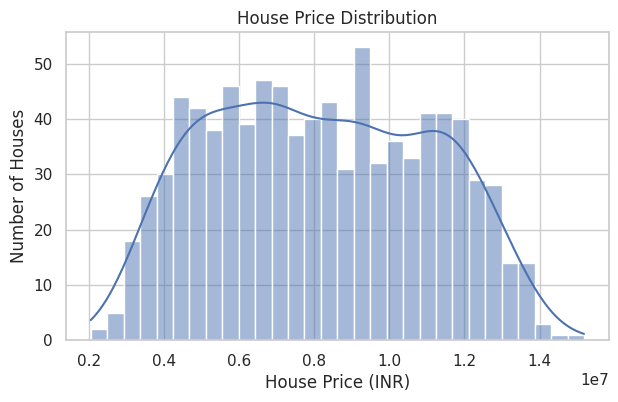

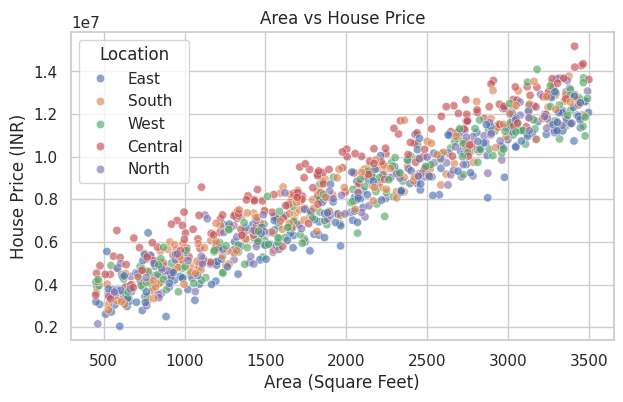

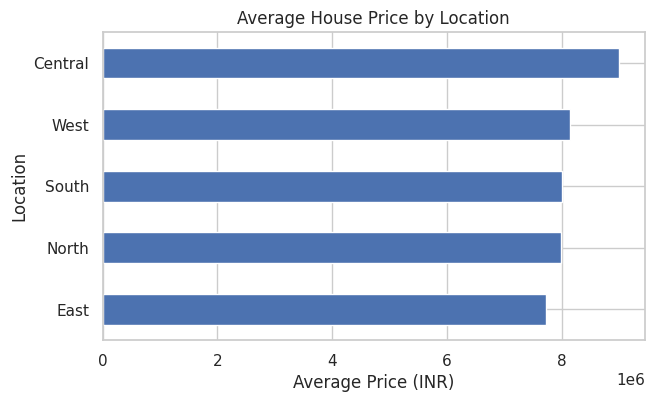

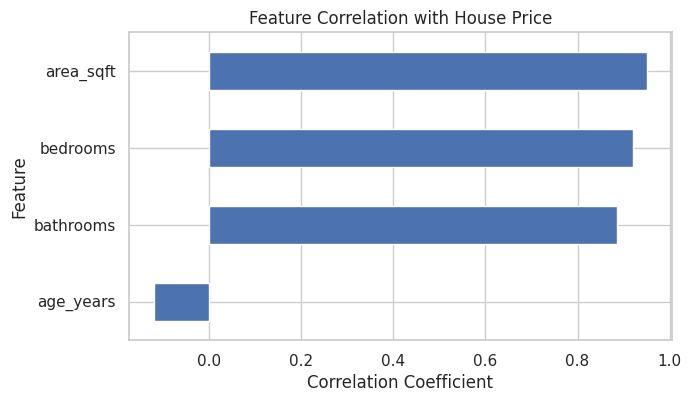

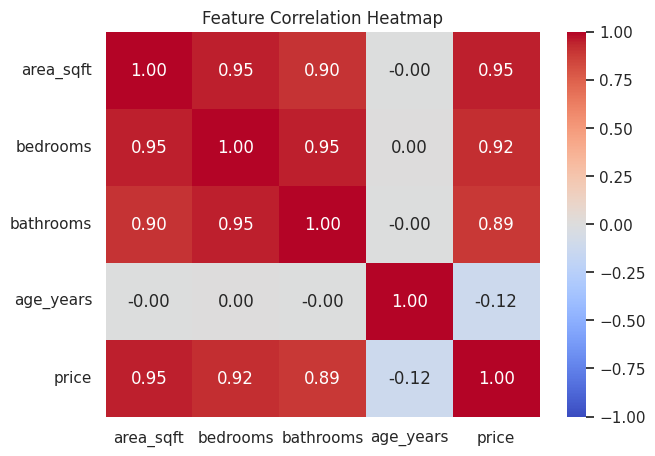

Model Evaluation Results:


,Model,MAE,R2
0,Linear Regression,491045.137,0.958
2,Random Forest,539893.480,0.948
1,Decision Tree,590756.592,0.938


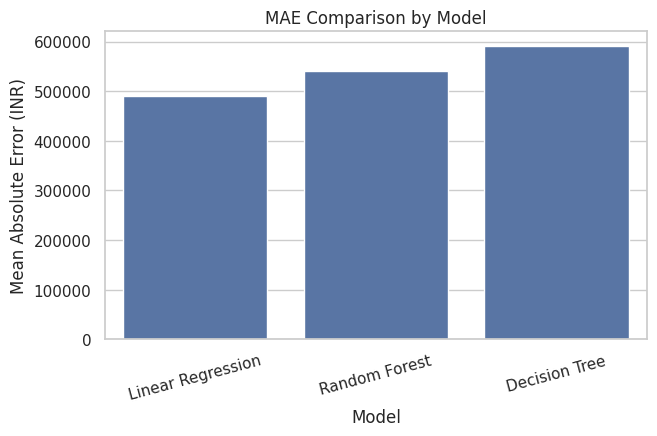

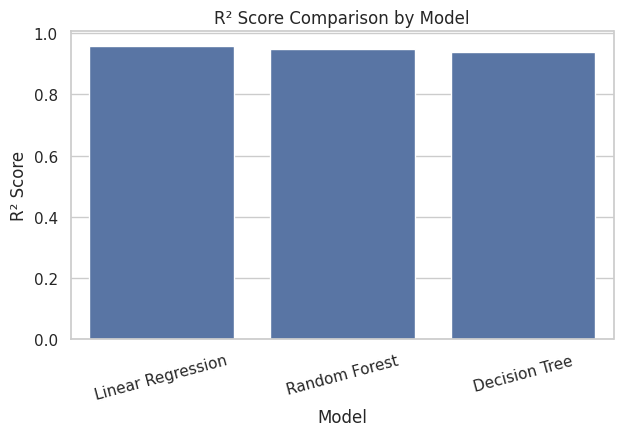

Best model by MAE: Linear Regression


In [1]:

# SMART HOUSE PRICE PREDICTION AND ANALYSIS
# Data Visualization and Model Comparison

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

# 1. Generate demo data (same logic as the original project)
rng = np.random.default_rng(42)
n = 900

locations = np.array(["Central", "North", "South", "East", "West"])
location = rng.choice(
    locations, size=n,
    p=[0.18, 0.20, 0.22, 0.20, 0.20]
)

area = rng.integers(450, 3500, size=n).astype(float)
bedrooms = np.clip(
    np.round(area / 550 + rng.normal(0, 0.5, n)), 1, 6
).astype(int)
bathrooms = np.clip(
    bedrooms - rng.integers(0, 2, n), 1, 5
).astype(int)
age = rng.integers(0, 45, size=n)

location_effect = pd.Series(location).map({
    "Central": 1800000,
    "North": 500000,
    "South": 900000,
    "East": 250000,
    "West": 700000
}).to_numpy()

price = (
    1800000 + area * 2400 + bedrooms * 250000
    + bathrooms * 180000 - age * 28000
    + location_effect + rng.normal(0, 650000, n)
)
price = np.maximum(price, 800000)

df = pd.DataFrame({
    "area_sqft": area,
    "bedrooms": bedrooms,
    "bathrooms": bathrooms,
    "age_years": age,
    "location": location,
    "price": price
})

print("Dataset shape:", df.shape)
display(df.head())

# 2. House Price Distribution
plt.figure(figsize=(7, 4))
sns.histplot(df["price"], bins=30, kde=True)
plt.title("House Price Distribution")
plt.xlabel("House Price (INR)")
plt.ylabel("Number of Houses")
plt.show()

# 3. Area vs House Price
plt.figure(figsize=(7, 4))
sns.scatterplot(
    data=df, x="area_sqft", y="price",
    hue="location", alpha=0.65
)
plt.title("Area vs House Price")
plt.xlabel("Area (Square Feet)")
plt.ylabel("House Price (INR)")
plt.legend(title="Location")
plt.show()

# 4. Average Price by Location
avg_price = (
    df.groupby("location")["price"]
    .mean().sort_values(ascending=False)
)
plt.figure(figsize=(7, 4))
avg_price.sort_values().plot(kind="barh")
plt.title("Average House Price by Location")
plt.xlabel("Average Price (INR)")
plt.ylabel("Location")
plt.show()

# 5. Feature Correlation with House Price
corr = df[
    ["area_sqft", "bedrooms", "bathrooms", "age_years", "price"]
].corr(numeric_only=True)

price_corr = corr["price"].drop("price").sort_values()
plt.figure(figsize=(7, 4))
price_corr.plot(kind="barh")
plt.title("Feature Correlation with House Price")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")
plt.show()

# 6. Feature Correlation Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f",
            vmin=-1, vmax=1)
plt.title("Feature Correlation Heatmap")
plt.show()

# 7. Train and Compare Models
features = [
    "area_sqft", "bedrooms", "bathrooms",
    "age_years", "location"
]
numeric = ["area_sqft", "bedrooms", "bathrooms", "age_years"]
categorical = ["location"]

X_train, X_test, y_train, y_test = train_test_split(
    df[features], df["price"],
    test_size=0.20, random_state=42
)

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical)
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=10, min_samples_leaf=3, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=180, min_samples_leaf=2,
        random_state=42, n_jobs=-1
    )
}

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "R2": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
print("Model Evaluation Results:")
display(results_df.round(3))

# 8. MAE Comparison
plt.figure(figsize=(7, 4))
sns.barplot(data=results_df, x="Model", y="MAE")
plt.title("MAE Comparison by Model")
plt.ylabel("Mean Absolute Error (INR)")
plt.xticks(rotation=15)
plt.show()

# 9. R² Comparison
plt.figure(figsize=(7, 4))
sns.barplot(data=results_df, x="Model", y="R2")
plt.title("R² Score Comparison by Model")
plt.ylabel("R² Score")
plt.xticks(rotation=15)
plt.show()

print("Best model by MAE:", results_df.iloc[0]["Model"])
